# Wine Dataset: K-Means vs GMM, and the Effect of PCA

**Roadmap**
1. Load data
2. Simple EDA
3. Preprocessing
4. K-Means vs GMM (including how to choose the number of clusters)
5. A small synthetic experiment: when does GMM win?
6. What PCA changes, and how it affects each algorithm
7. Choosing the number of PCA components
8. Summary

> The dataset has **no label used for fitting**. The wine `target` (3 cultivars) is only used afterwards as an *external check* (Adjusted Rand Index) to see whether the discovered clusters make sense.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, davies_bouldin_score
from sklearn.datasets import load_wine, make_blobs

sns.set_theme(style="whitegrid", context="notebook")
RS = 42

## 1. Load Data

In [2]:
# Kaggle file "wine-clustering.csv" (harrywang/wine-dataset-for-clustering) is the classic UCI Wine data.
# If the CSV is next to the notebook we use it; otherwise we fall back to the identical copy inside scikit-learn.
import os
true_labels = None
if os.path.exists("wine-clustering.csv"):
    df = pd.read_csv("wine-clustering.csv")
    print("Loaded Kaggle CSV")
else:
    w = load_wine(as_frame=True)
    df = w.data.copy()
    print("Kaggle CSV not found -> using sklearn's copy of the same dataset")

# Cultivar labels are only available in the sklearn copy; used ONLY for evaluation.
true_labels = load_wine().target

df.columns = [c.strip() for c in df.columns]
df.head()

Loaded Kaggle CSV


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


## 2. Simple EDA

In [3]:
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
df.describe().T[["mean","std","min","max"]].round(2)

Shape: (178, 13)
Missing values: 0 | Duplicate rows: 0


,mean,std,min,max
Alcohol,13.00,0.81,11.03,14.83
Malic_Acid,2.34,1.12,0.74,5.80
Ash,2.37,0.27,1.36,3.23
Ash_Alcanity,19.49,3.34,10.60,30.00
Magnesium,99.74,14.28,70.00,162.00
Total_Phenols,2.30,0.63,0.98,3.88
Flavanoids,2.03,1.00,0.34,5.08
Nonflavanoid_Phenols,0.36,0.12,0.13,0.66
Proanthocyanins,1.59,0.57,0.41,3.58
Color_Intensity,5.06,2.32,1.28,13.00


**Observation:** the features live on very different scales (e.g. `proline` is in the hundreds/thousands while `hue` is around 1). Any distance-based method will be dominated by the large-scale features unless we standardise.

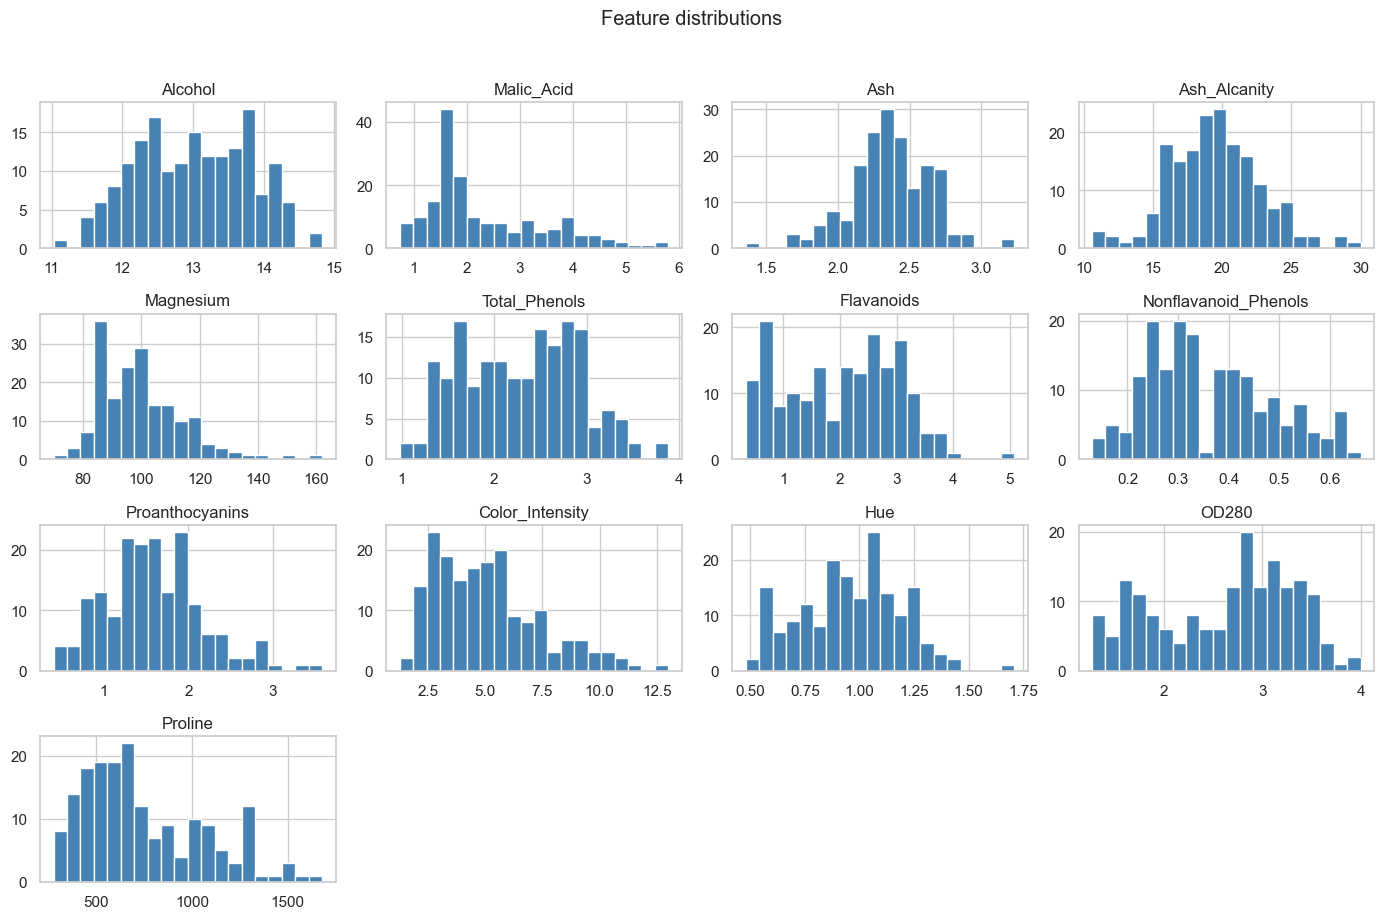

In [4]:
df.hist(bins=20, figsize=(14,9), color="steelblue", edgecolor="white")
plt.suptitle("Feature distributions", y=1.02); plt.tight_layout(); plt.show()

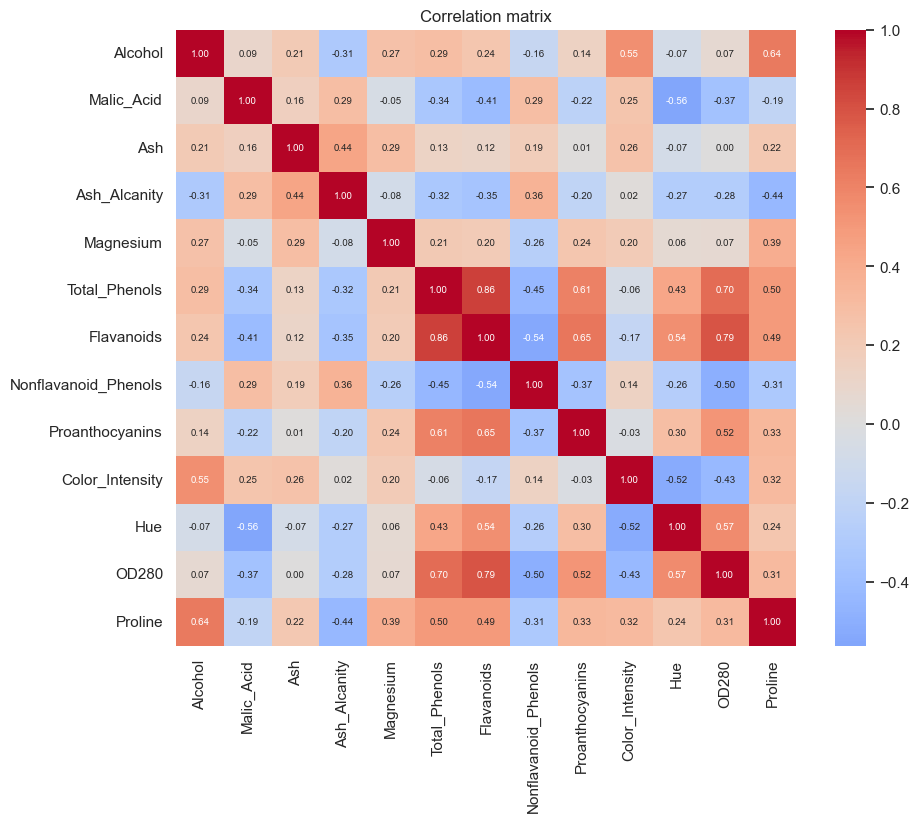

In [5]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size":7})
plt.title("Correlation matrix"); plt.show()

**Observation:** several features are strongly correlated (e.g. `flavanoids`, `total_phenols`, `od280/od315...`). Correlated features mean redundant information, which is exactly what PCA compresses, and it also means clusters can be tilted/elongated rather than spherical.

## 3. Preprocessing
Both K-Means (Euclidean distance) and GMM (Gaussian likelihoods) are sensitive to scale, and PCA is variance-based so it would simply pick the biggest-variance raw feature (`proline`). We therefore **standardise** (zero mean, unit variance).

In [6]:
X_raw = df.values
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

# PCA on UNscaled data would be dominated by one feature:
pca_raw = PCA().fit(X_raw)
print("PC1 explained variance WITHOUT scaling:", round(pca_raw.explained_variance_ratio_[0],3))
print("PC1 explained variance WITH scaling   :", round(PCA().fit(X).explained_variance_ratio_[0],3))

PC1 explained variance WITHOUT scaling: 0.998
PC1 explained variance WITH scaling   : 0.362


## 4. K-Means vs GMM

| | K-Means | GMM |
|---|---|---|
| Model | Hard assignment to nearest centroid | Mixture of Gaussians, each point has a *probability* of belonging to each component |
| Cluster shape | Implicitly **spherical**, equal size/variance (it minimises within-cluster squared Euclidean distance) | Each component has its own **mean + covariance** -> ellipses of different size, orientation and weight |
| Output | Labels | Labels + soft probabilities + a likelihood (so BIC/AIC can be computed) |
| Fitting | Lloyd's algorithm | EM algorithm (K-Means is actually the special case of GMM with equal spherical covariance and hard assignment) |

### 4.1 Choosing the number of clusters
- **K-Means:** elbow (inertia) + silhouette score.
- **GMM:** BIC / AIC (a *likelihood-based* criterion that penalises the number of parameters), plus silhouette.

  File "d:\testdata1\.venv1\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\adham\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\adham\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\adham\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


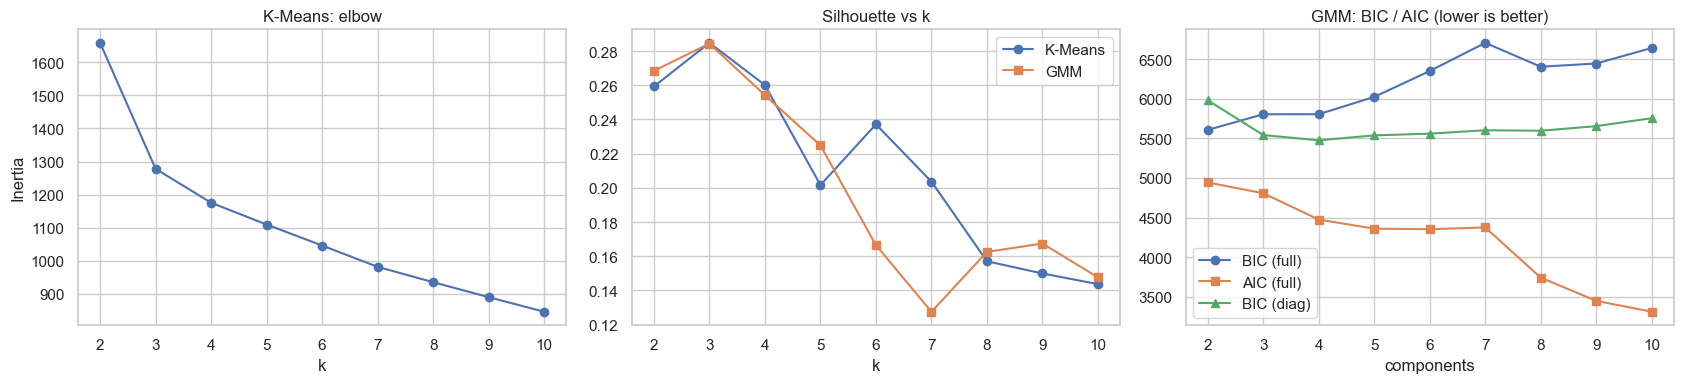

Best k by silhouette (K-Means): 3
Best k by BIC (GMM, full cov) : 2
Best k by BIC (GMM, diag cov) : 4


In [7]:
ks = range(2, 11)
inertia, sil_km, bic, aic, bic_diag, sil_gm = [], [], [], [], [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=RS).fit(X)
    inertia.append(km.inertia_); sil_km.append(silhouette_score(X, km.labels_))
    gm = GaussianMixture(k, covariance_type="full", n_init=5, random_state=RS).fit(X)
    bic_diag.append(GaussianMixture(k, covariance_type="diag", n_init=5, random_state=RS).fit(X).bic(X))
    bic.append(gm.bic(X)); aic.append(gm.aic(X)); sil_gm.append(silhouette_score(X, gm.predict(X)))

fig, ax = plt.subplots(1, 3, figsize=(17,4))
ax[0].plot(ks, inertia, "o-"); ax[0].set(title="K-Means: elbow", xlabel="k", ylabel="Inertia")
ax[1].plot(ks, sil_km, "o-", label="K-Means"); ax[1].plot(ks, sil_gm, "s-", label="GMM")
ax[1].set(title="Silhouette vs k", xlabel="k"); ax[1].legend()
ax[2].plot(ks, bic, "o-", label="BIC (full)"); ax[2].plot(ks, aic, "s-", label="AIC (full)"); ax[2].plot(ks, bic_diag, "^-", label="BIC (diag)")
ax[2].set(title="GMM: BIC / AIC (lower is better)", xlabel="components"); ax[2].legend()
plt.tight_layout(); plt.show()
print("Best k by silhouette (K-Means):", list(ks)[int(np.argmax(sil_km))])
print("Best k by BIC (GMM, full cov) :", list(ks)[int(np.argmin(bic))])
print("Best k by BIC (GMM, diag cov) :", list(ks)[int(np.argmin(bic_diag))])

The elbow and silhouette point to **k = 3** (which matches the 3 known cultivars). BIC/AIC come for free with GMM because it is a probabilistic model, whereas K-Means has no likelihood and relies on heuristics.

**Important caveat:** BIC for the *full-covariance* GMM prefers a smaller k here. With 13 features each component needs a 13x13 covariance (91 + 13 mean parameters) but we have only 178 samples, so BIC heavily penalises extra components. The more constrained `diag` GMM (far fewer parameters) is much closer to k = 3 (it picks 3-4; compare the BIC values at k = 3 and 4). This is the first sign that **model complexity vs. dimensionality matters**, which is exactly what PCA affects in section 6.

### 4.2 Fit both models with k = 3 and compare

In [8]:
K = 3
km = KMeans(K, n_init=10, random_state=RS).fit(X)
gm = GaussianMixture(K, covariance_type="full", n_init=5, random_state=RS).fit(X)
lab_km, lab_gm = km.labels_, gm.predict(X)

def report(name, Xs, labels):
    return {"Model": name,
            "Silhouette": silhouette_score(Xs, labels),
            "Davies-Bouldin (lower=better)": davies_bouldin_score(Xs, labels),
            "ARI vs cultivar": adjusted_rand_score(true_labels, labels)}

pd.DataFrame([report("K-Means", X, lab_km), report("GMM (full)", X, lab_gm)]).round(3)

,Model,Silhouette,Davies-Bouldin (lower=better),ARI vs cultivar
0,K-Means,0.285,1.389,0.897
1,GMM (full),0.284,1.394,0.880


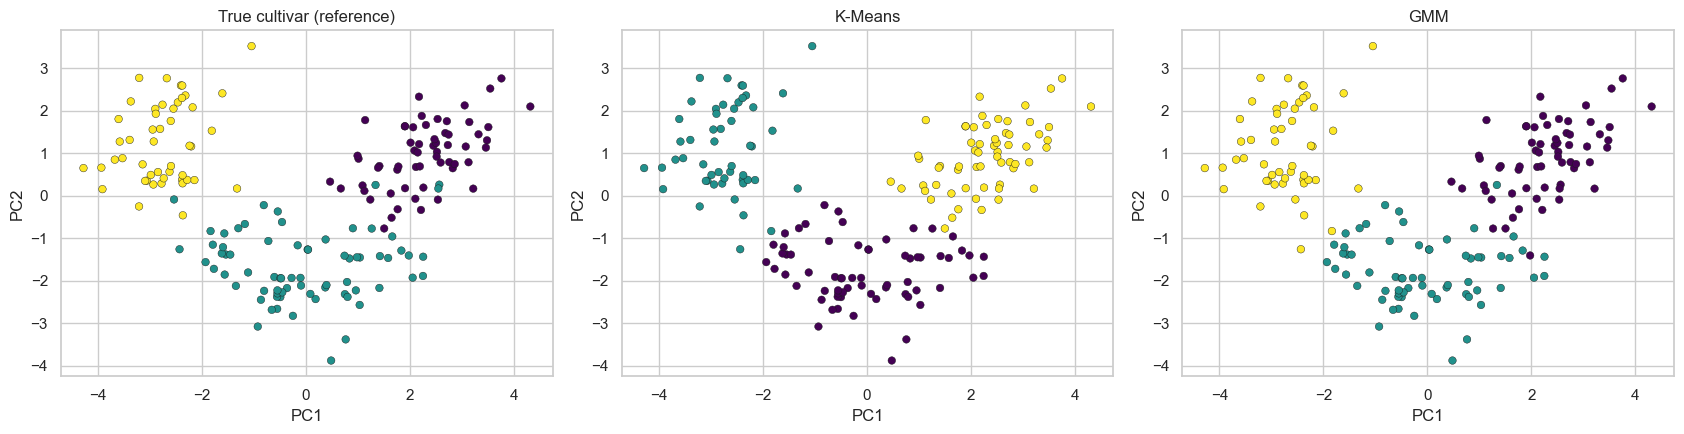

In [9]:
# 2D view (PCA is used here ONLY for plotting; clustering above was done on the full 13-D data)
Z2 = PCA(2, random_state=RS).fit_transform(X)
fig, ax = plt.subplots(1, 3, figsize=(17,4.5))
for a, lab, t in zip(ax, [true_labels, lab_km, lab_gm], ["True cultivar (reference)", "K-Means", "GMM"]):
    a.scatter(Z2[:,0], Z2[:,1], c=lab, cmap="viridis", s=30, edgecolor="k", linewidth=.3)
    a.set(title=t, xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.show()

Points with max-probability < 0.9 (ambiguous): 1 of 178


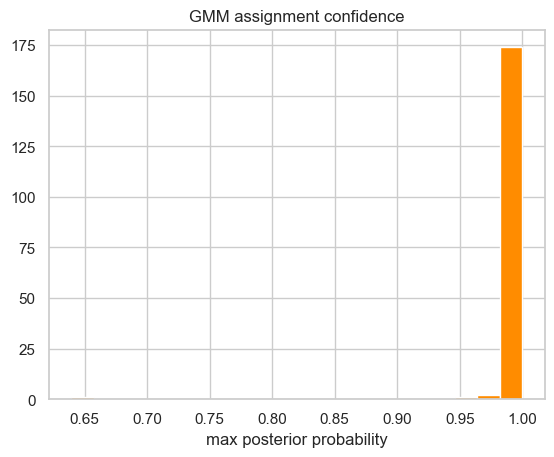

In [10]:
# GMM gives soft assignments: how confident is it?
proba = gm.predict_proba(X)
conf = proba.max(axis=1)
print(f"Points with max-probability < 0.9 (ambiguous): {(conf<0.9).sum()} of {len(X)}")
plt.hist(conf, bins=20, color="darkorange", edgecolor="white")
plt.title("GMM assignment confidence"); plt.xlabel("max posterior probability"); plt.show()

On this (fairly clean, well-separated) dataset K-Means and GMM perform similarly. The real difference between them is *what they can represent* — which we show next with a controlled experiment.

## 5. Why can GMM find clusters that K-Means cannot?
K-Means only draws **linear, equidistant boundaries between centroids**, so it implicitly assumes round clusters of equal size. A GMM learns a covariance matrix per component, so it can model **elongated, tilted, and different-sized** clusters.
We show it on synthetic data where we know the truth.

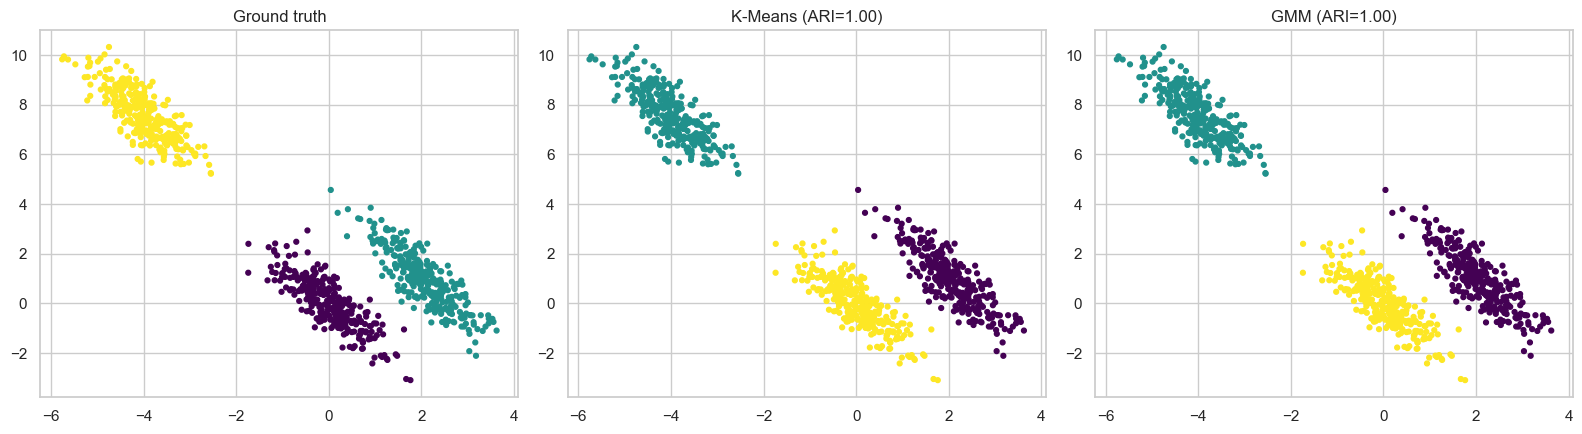

In [11]:
Xb, yb = make_blobs(n_samples=900, centers=[[0,0],[5,5],[-5,5]], cluster_std=[1.0,1.0,1.0], random_state=RS)
Xb = Xb @ np.array([[0.6, -0.65],[-0.2, 0.85]])          # stretch + rotate -> elongated, correlated clusters

km_b = KMeans(3, n_init=10, random_state=RS).fit(Xb)
gm_b = GaussianMixture(3, covariance_type="full", n_init=5, random_state=RS).fit(Xb)

fig, ax = plt.subplots(1, 3, figsize=(16,4.5))
for a, lab, t in zip(ax, [yb, km_b.labels_, gm_b.predict(Xb)],
        ["Ground truth", f"K-Means (ARI={adjusted_rand_score(yb, km_b.labels_):.2f})",
         f"GMM (ARI={adjusted_rand_score(yb, gm_b.predict(Xb)):.2f})"]):
    a.scatter(Xb[:,0], Xb[:,1], c=lab, cmap="viridis", s=12); a.set_title(t)
plt.tight_layout(); plt.show()

**Takeaway:** K-Means cuts the elongated clusters with straight "Voronoi" boundaries and mixes them; GMM recovers them because its covariance matrices capture the stretch/rotation. The price: GMM has many more parameters (a full covariance is $d(d+1)/2$ per component), so it needs more data and can overfit in high dimensions, which is where PCA becomes relevant.

## 6. What does PCA actually change?
PCA is a **rotation** of the (standardised) data to new orthogonal axes, ordered by the variance they capture:
- the new features (PCs) are **linear combinations** of the originals;
- they are **uncorrelated** (the covariance matrix of the PCA scores is diagonal);
- keeping only the first *m* PCs **discards the low-variance directions** (reducing dimension, removing some noise, but also possibly removing small-variance directions that carry cluster information).

PCA does **not** use cluster information. It only looks at variance, so "high variance" ≠ "good for clustering".

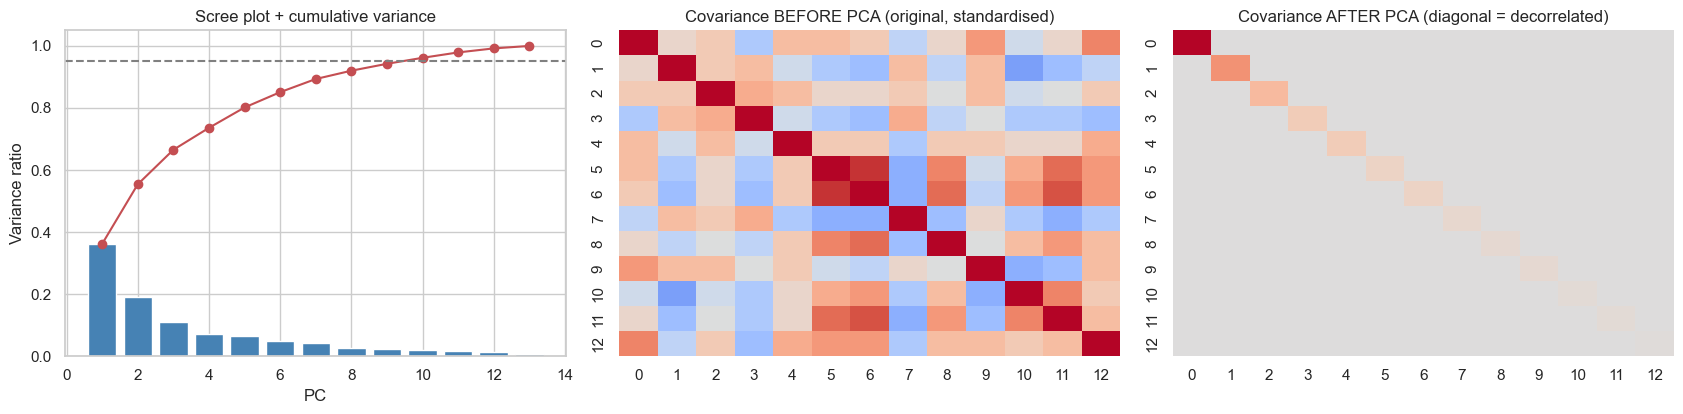

Components for 80% / 90% / 95% variance: [5, 8, 10]


In [12]:
pca = PCA(random_state=RS).fit(X)
evr = pca.explained_variance_ratio_; cum = np.cumsum(evr)

fig, ax = plt.subplots(1, 3, figsize=(17,4.3))
ax[0].bar(range(1,14), evr, color="steelblue"); ax[0].plot(range(1,14), cum, "ro-")
ax[0].axhline(.95, ls="--", c="gray"); ax[0].set(title="Scree plot + cumulative variance", xlabel="PC", ylabel="Variance ratio")
Zp = pca.transform(X)
sns.heatmap(pd.DataFrame(np.cov(X.T)).round(1), ax=ax[1], cmap="coolwarm", center=0, cbar=False)
ax[1].set_title("Covariance BEFORE PCA (original, standardised)")
sns.heatmap(pd.DataFrame(np.cov(Zp.T)).round(1), ax=ax[2], cmap="coolwarm", center=0, cbar=False)
ax[2].set_title("Covariance AFTER PCA (diagonal = decorrelated)")
plt.tight_layout(); plt.show()
print("Components for 80% / 90% / 95% variance:", [int(np.searchsorted(cum, t)+1) for t in (.8,.9,.95)])

In [13]:
loadings = pd.DataFrame(pca.components_[:2].T, index=df.columns, columns=["PC1","PC2"])
loadings.sort_values("PC1").round(2).T.style.background_gradient(cmap="coolwarm", axis=1)

,Nonflavanoid_Phenols,Malic_Acid,Ash_Alcanity,Color_Intensity,Ash,Magnesium,Alcohol,Proline,Hue,Proanthocyanins,OD280,Total_Phenols,Flavanoids
PC1,-0.300000,-0.250000,-0.240000,-0.090000,-0.000000,0.140000,0.140000,0.290000,0.300000,0.310000,0.380000,0.390000,0.420000
PC2,0.030000,0.220000,-0.010000,0.530000,0.320000,0.300000,0.480000,0.360000,-0.280000,0.040000,-0.160000,0.070000,-0.000000


PC1 and PC2 are mixtures of correlated chemical features (e.g. phenols/flavanoids vs. colour intensity), so they summarise the main axes of variation in the wines.

### 6.1 Does PCA improve clustering? Is the effect the same for K-Means and GMM?
We cluster in PCA space using the first *m* components, for *m* = 2…13 (13 = all components = same information as the original data, just rotated), and track silhouette (internal measure) and ARI (external check).

Two GMM variants are used:
- `full`: each component has a full covariance matrix, which *can* model correlations on its own.
- `diag`: each component has only a diagonal covariance, which *cannot* model correlations. After PCA the **global** covariance is diagonal, so this is where PCA should help GMM most.

ARI with NO PCA (all 13 original features): {'K-Means': 0.897, 'GMM full': 0.88, 'GMM diag': 0.915}


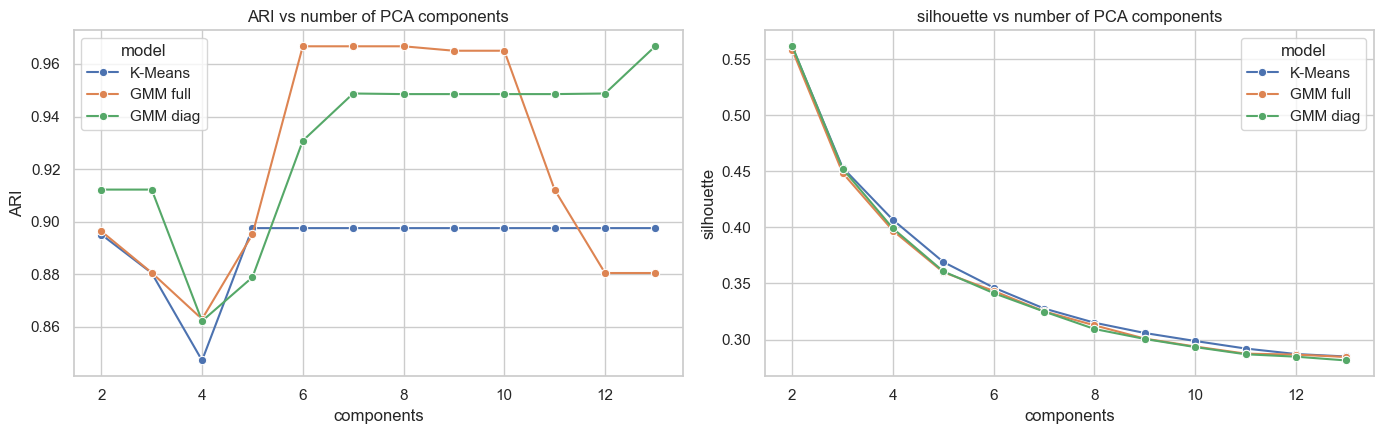

model,GMM diag,GMM full,K-Means
components,,,
2,0.912,0.896,0.895
3,0.912,0.881,0.880
4,0.862,0.863,0.847
5,0.879,0.895,0.897
6,0.931,0.967,0.897
7,0.949,0.967,0.897
8,0.949,0.967,0.897
9,0.949,0.965,0.897
10,0.949,0.965,0.897


In [14]:
rows = []
for m in range(2, 14):
    Zm = PCA(m, random_state=RS).fit_transform(X)
    for name, model in [
        ("K-Means", KMeans(3, n_init=10, random_state=RS)),
        ("GMM full", GaussianMixture(3, covariance_type="full", n_init=5, random_state=RS)),
        ("GMM diag", GaussianMixture(3, covariance_type="diag", n_init=5, random_state=RS)),
    ]:
        lab = model.fit_predict(Zm)
        rows.append(dict(components=m, model=name,
                         silhouette=silhouette_score(Zm, lab),
                         ARI=adjusted_rand_score(true_labels, lab)))
res = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(14,4.5))
for metric, a in zip(["ARI", "silhouette"], ax):
    sns.lineplot(data=res, x="components", y=metric, hue="model", marker="o", ax=a)
    a.set_title(f"{metric} vs number of PCA components")
# reference lines: no PCA
base = {n: adjusted_rand_score(true_labels, l) for n, l in
        [("K-Means", lab_km), ("GMM full", lab_gm),
         ("GMM diag", GaussianMixture(3, covariance_type="diag", n_init=5, random_state=RS).fit_predict(X))]}
print("ARI with NO PCA (all 13 original features):", {k: round(v,3) for k,v in base.items()})
plt.tight_layout(); plt.show()
res.pivot(index="components", columns="model", values="ARI").round(3)

**How to read this**
- Compare with the "no PCA" ARI printed above: GMM `diag` improves when we simply rotate to all 13 PCs (nothing is dropped), while K-Means and GMM `full` do not change at all. GMM `full` improves only when we reduce dimensions.
- Silhouette is computed *inside each space*, so it naturally tends to look better in lower dimensions (distances concentrate less, fewer noisy directions). It is **not** directly comparable across different *m*, so use it cautiously. ARI against the known cultivars is a fairer external check here.
- PCA does **not** guarantee improvement: with too few components we throw away discriminative variance; with all components nothing changes for K-Means (rotation preserves Euclidean distances, so K-Means on all PCs ≡ K-Means on the original data).
- It affects the two algorithms differently:
  - **K-Means** is rotation-invariant, so it only changes when we *drop* components (it benefits only if the dropped directions were noise).
  - **GMM** is sensitive to the *basis* when its covariance is constrained: with `diag` covariance, PCA's decorrelated axes match the model's assumptions much better. With `full` covariance, rotating changes nothing (a full covariance is rotation-equivariant), and PCA mainly helps by **reducing the number of parameters** (fewer components -> smaller covariance matrices -> less overfitting).

### 6.2 Visualising the effect with 2 PCs

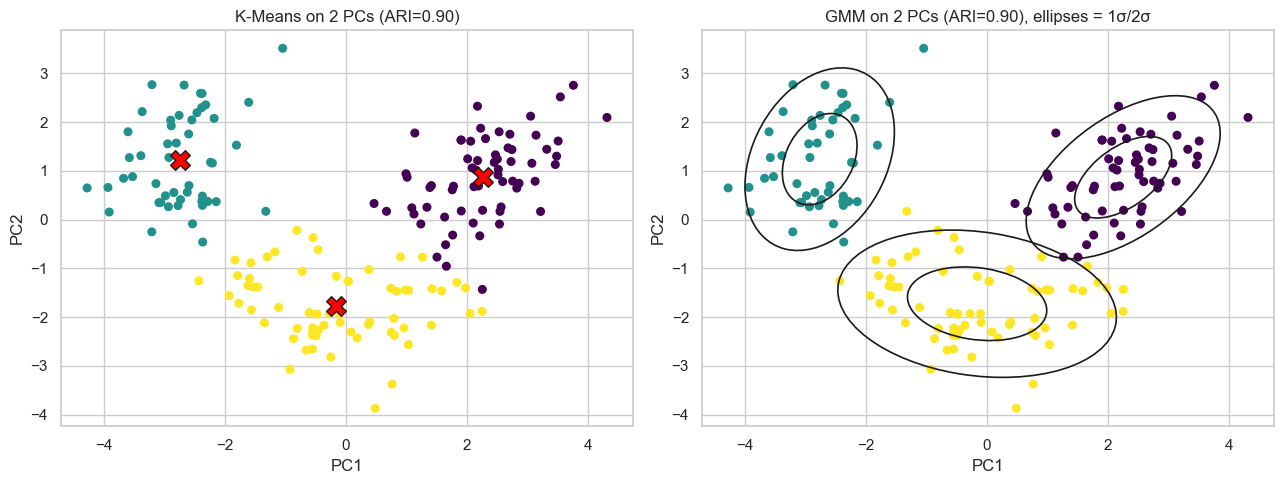

In [15]:
Z2 = PCA(2, random_state=RS).fit_transform(X)
km2 = KMeans(3, n_init=10, random_state=RS).fit(Z2)
gm2 = GaussianMixture(3, covariance_type="full", n_init=5, random_state=RS).fit(Z2)

from matplotlib.patches import Ellipse
def draw_gmm(ax, g):
    for mu, cov in zip(g.means_, g.covariances_):
        vals, vecs = np.linalg.eigh(cov); ang = np.degrees(np.arctan2(*vecs[:,1][::-1]))
        for n in (1, 2):
            ax.add_patch(Ellipse(mu, 2*n*np.sqrt(vals[1]), 2*n*np.sqrt(vals[0]), angle=ang, fill=False, ec="k", lw=1.2))

fig, ax = plt.subplots(1, 2, figsize=(13,5))
ax[0].scatter(Z2[:,0], Z2[:,1], c=km2.labels_, cmap="viridis", s=30)
ax[0].scatter(*km2.cluster_centers_.T, marker="X", s=200, c="red", ec="k"); ax[0].set_title(f"K-Means on 2 PCs (ARI={adjusted_rand_score(true_labels, km2.labels_):.2f})")
ax[1].scatter(Z2[:,0], Z2[:,1], c=gm2.predict(Z2), cmap="viridis", s=30); draw_gmm(ax[1], gm2)
ax[1].set_title(f"GMM on 2 PCs (ARI={adjusted_rand_score(true_labels, gm2.predict(Z2)):.2f}), ellipses = 1σ/2σ")
for a in ax: a.set(xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.show()

## 7. How do we choose the number of clusters / components?

**Two different choices:**
1. **Number of clusters *k*** (K-Means) / **mixture components** (GMM): elbow, silhouette, **BIC/AIC** (GMM only).
2. **Number of PCA components *m***: scree plot / elbow, cumulative explained variance threshold (e.g. 90-95%), or evaluate the downstream clustering quality as we did in section 6.1.

They interact: after choosing *m*, we should re-check *k* in the reduced space.

Using m = 8 PCs (>=90% variance). Re-checking k in this reduced space...


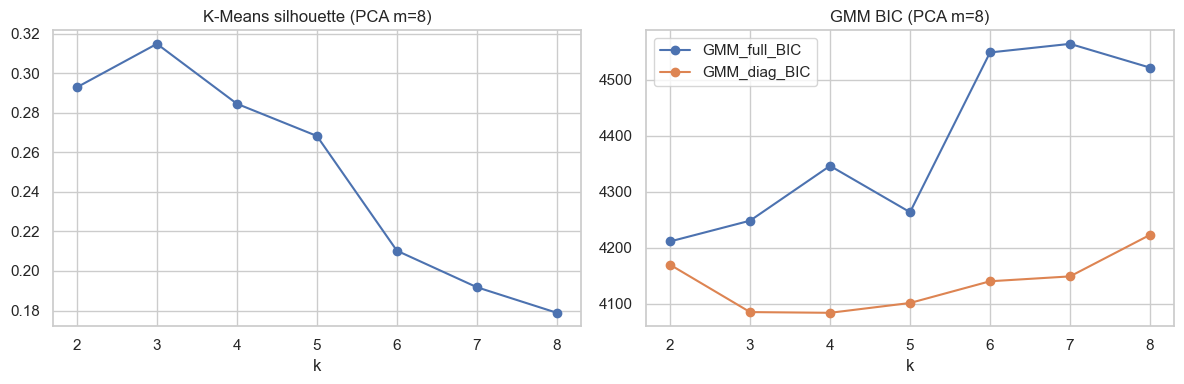

,KMeans_silhouette,GMM_full_BIC,GMM_diag_BIC
k,,,
2,0.3,4211.1,4169.5
3,0.3,4248.2,4085.0
4,0.3,4346.1,4083.7
5,0.3,4263.3,4101.2
6,0.2,4548.6,4140.0
7,0.2,4564.0,4148.7
8,0.2,4521.5,4222.8


In [16]:
m = int(np.searchsorted(cum, .90) + 1)         # 90% variance rule
Zm = PCA(m, random_state=RS).fit_transform(X)
print(f"Using m = {m} PCs (>=90% variance). Re-checking k in this reduced space...")

ks = range(2, 9); out = []
for k in ks:
    km_ = KMeans(k, n_init=10, random_state=RS).fit(Zm)
    gm_ = GaussianMixture(k, covariance_type="full", n_init=5, random_state=RS).fit(Zm)
    gd_ = GaussianMixture(k, covariance_type="diag", n_init=5, random_state=RS).fit(Zm)
    out.append(dict(k=k, KMeans_silhouette=silhouette_score(Zm, km_.labels_),
                    GMM_full_BIC=gm_.bic(Zm), GMM_diag_BIC=gd_.bic(Zm)))
out = pd.DataFrame(out).set_index("k")

fig, ax = plt.subplots(1, 2, figsize=(12,4))
out["KMeans_silhouette"].plot(marker="o", ax=ax[0], title=f"K-Means silhouette (PCA m={m})")
out[["GMM_full_BIC","GMM_diag_BIC"]].plot(marker="o", ax=ax[1], title=f"GMM BIC (PCA m={m})")
plt.tight_layout(); plt.show()
out.round(1)

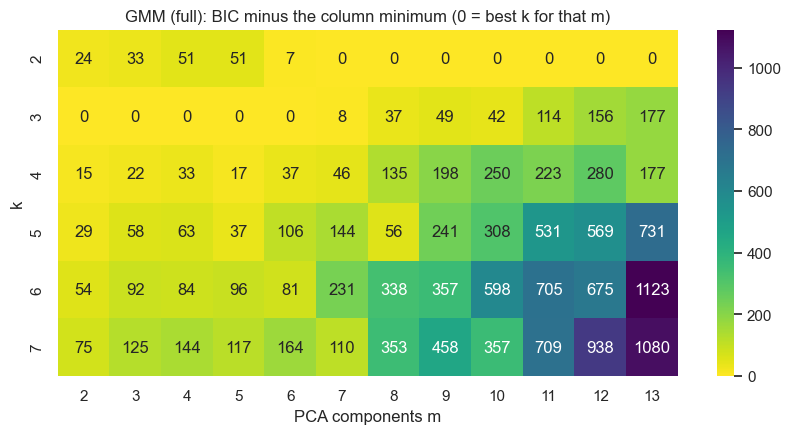

In [17]:
# Joint view: BIC of GMM over (PCA components, k)
def bic_for(m_, k):
    Zq = PCA(m_, random_state=RS).fit_transform(X)
    return GaussianMixture(k, covariance_type="full", n_init=3, random_state=RS).fit(Zq).bic(Zq)
grid = pd.DataFrame({m_: [bic_for(m_, k) for k in range(2, 8)] for m_ in range(2, 14)}, index=range(2, 8))
# NOTE: BIC is only comparable for models fit on the SAME data, so we read each column (fixed m) separately.
plt.figure(figsize=(10,4.5))
sns.heatmap(grid.sub(grid.min(axis=0), axis=1), annot=True, fmt=".0f", cmap="viridis_r")
plt.title("GMM (full): BIC minus the column minimum (0 = best k for that m)"); plt.xlabel("PCA components m"); plt.ylabel("k"); plt.show()

## 8. Summary — answers to the learning objectives

**How does K-Means differ from GMM?**
K-Means is a hard-assignment, centroid-based method that minimises within-cluster squared distance (implicitly assumes round, equal-size clusters). GMM is a probabilistic model: each cluster is a Gaussian with its own mean, covariance and weight, fitted by EM, producing soft probabilities and a likelihood.

**Why can GMM find clusters K-Means cannot?**
Because of per-component covariance matrices: GMM can represent elongated, rotated and different-sized clusters, while K-Means' boundaries are straight lines equidistant to centroids (section 5). On the clean, well-separated wine data they perform similarly; the gap appears when cluster shapes are non-spherical.

**What does PCA actually change in the data?**
It rotates the standardised data to uncorrelated axes ordered by variance; the covariance becomes diagonal. Dropping the last components reduces dimension and noise, but PCA ignores cluster structure, so low-variance directions that separate clusters can be lost. Without scaling, PCA is dominated by the largest-scale feature (`proline`).

**Does PCA always improve clustering?**
No. It can help (noise removal, fewer GMM parameters, better-conditioned distances) or hurt (too few components remove useful information). With all components kept, K-Means is unchanged. Always verify with an evaluation, as in section 6.1.

**Does PCA affect K-Means and GMM in the same way?**
No. K-Means is rotation-invariant, so only *dimensionality reduction* matters. GMM also depends on its covariance structure: PCA helps most with `diag` covariance (decorrelated axes match the assumption) and, for `full` covariance, mainly by cutting the number of parameters.

**How do we choose the number of clusters/components?**
*Clusters:* elbow, silhouette, and BIC/AIC (for GMM). *PCA components:* scree plot, cumulative variance (90-95%), or downstream clustering performance. Check *k* again after reducing dimension. Here the elbow, silhouette, and the diag-covariance BIC (3-4) are consistent with **k = 3**, while the full-covariance BIC in 13-D is biased toward fewer components because of its parameter count. For PCA, ~8 PCs give 90% of the variance, and GMM/K-Means performance is already good with 2-3 PCs and around 6-10 PCs for GMM, which shows that variance explained and clustering quality are related but not identical criteria.